# U-Net training — Sen-2 LULC

Trains a U-Net for semantic segmentation on the Mendeley "Sen-2 LULC" dataset
(64x64 RGB chips, 7 land-cover classes, mask labels 1-7 with no background class).
This is a baseline model trained on RGB India chips before swapping in
Kenya-specific Sentinel-2 multispectral chips later, per the project README.

## Imports

In [1]:
import os
from pathlib import Path

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

## Configuration

Dataset paths, image size, and class names. Mask pixel values are 1-7 (no
background/0 class), so labels get remapped to 0-6 during loading to work
with `sparse_categorical_crossentropy` and `MeanIoU`.

In [ ]:
DATASET_ROOT = Path('data/Sen-2 LULC')

TRAIN_IMG_DIR = DATASET_ROOT / 'train_images' / 'train'
TRAIN_MASK_DIR = DATASET_ROOT / 'train_masks' / 'train'
VAL_IMG_DIR = DATASET_ROOT / 'val_images' / 'val'
VAL_MASK_DIR = DATASET_ROOT / 'val_masks' / 'val'
TEST_IMG_DIR = DATASET_ROOT / 'test_images' / 'test'
TEST_MASK_DIR = DATASET_ROOT / 'test_masks' / 'test'

IMG_SIZE = 64
N_CHANNELS = 3
BATCH_SIZE = 64

CLASS_NAMES = [
    'water',
    'dense forest',
    'sparse forest',
    'barren land',
    'built up',
    'agriculture',
    'fallow land',
]
N_CLASSES = len(CLASS_NAMES)

## Pairing images with masks

Images are `.png`, masks are `.tif`, but they share the same filename stem.
Build matched, sorted lists of paths for each split so image[i] and mask[i]
always correspond.

In [3]:
def pair_paths(img_dir, mask_dir):
    img_paths = sorted(img_dir.glob('*.png'), key=lambda p: p.stem)
    mask_by_stem = {p.stem: p for p in mask_dir.glob('*.tif')}
    pairs = [(str(p), str(mask_by_stem[p.stem])) for p in img_paths if p.stem in mask_by_stem]
    images, masks = zip(*pairs)
    return list(images), list(masks)

train_img_paths, train_mask_paths = pair_paths(TRAIN_IMG_DIR, TRAIN_MASK_DIR)
val_img_paths, val_mask_paths = pair_paths(VAL_IMG_DIR, VAL_MASK_DIR)
test_img_paths, test_mask_paths = pair_paths(TEST_IMG_DIR, TEST_MASK_DIR)

print(f'train: {len(train_img_paths)} pairs')
print(f'val:   {len(val_img_paths)} pairs')
print(f'test:  {len(test_img_paths)} pairs')

train: 149600 pairs
val:   32079 pairs
test:  32079 pairs


## Loading and decoding

PNG images decode natively with `tf.image`, but TensorFlow has no built-in
TIFF decoder, so masks are read with PIL inside a `tf.numpy_function`. Images
are scaled to [0, 1]; mask labels are shifted from 1-7 to 0-6.

In [4]:
def _read_mask(path):
    return np.array(Image.open(path.decode('utf-8')), dtype=np.uint8)

def load_pair(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=N_CHANNELS)
    img = tf.cast(img, tf.float32) / 255.0
    img.set_shape([IMG_SIZE, IMG_SIZE, N_CHANNELS])

    mask = tf.numpy_function(_read_mask, [mask_path], tf.uint8)
    mask.set_shape([IMG_SIZE, IMG_SIZE])
    mask = tf.cast(mask, tf.int32) - 1
    # A few chips contain stray 0 (nodata/edge) pixels that become -1 after the
    # shift and crash tf.gather in the loss; clamp them into the valid range.
    mask = tf.clip_by_value(mask, 0, N_CLASSES - 1)
    mask = tf.expand_dims(mask, axis=-1)

    return img, mask

## Augmentation

Light, spectrally-safe augmentation only (flips and 90-degree rotations) —
no color jitter, since hue/brightness shifts would distort the spectral
signal that later needs to transfer to real Sentinel-2 bands.

In [5]:
def augment(img, mask):
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_left_right(img)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_up_down(img)
        mask = tf.image.flip_up_down(mask)

    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    img = tf.image.rot90(img, k=k)
    mask = tf.image.rot90(mask, k=k)

    return img, mask

## Building the `tf.data` pipelines

Train, validation, and test sets as `tf.data.Dataset` objects. Augmentation
and shuffling are only applied to the training set.

In [ ]:
def make_dataset(img_paths, mask_paths, training=False):
    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    ds = ds.map(load_pair, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(buffer_size=200)
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# Train on a random subset for fast CPU iteration. Set SUBSET = None to use the
# full dataset (e.g. on a GPU runtime).
# SUBSET = {'train': 1200, 'val': 300}
SUBSET = None

def subsample(img_paths, mask_paths, n, seed=0):
    if n is None or n >= len(img_paths):
        return img_paths, mask_paths
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(img_paths), size=n, replace=False)
    return [img_paths[i] for i in idx], [mask_paths[i] for i in idx]

train_sub_imgs, train_sub_masks = subsample(
    train_img_paths, train_mask_paths, SUBSET['train'] if SUBSET else None,
)
val_sub_imgs, val_sub_masks = subsample(
    val_img_paths, val_mask_paths, SUBSET['val'] if SUBSET else None,
)
print(f'training on {len(train_sub_imgs)} / {len(train_img_paths)} train chips, '
      f'{len(val_sub_imgs)} / {len(val_img_paths)} val chips')

train_ds = make_dataset(train_sub_imgs, train_sub_masks, training=True)
val_ds = make_dataset(val_sub_imgs, val_sub_masks)
test_ds = make_dataset(test_img_paths, test_mask_paths)

## Sanity check

Decode a few batches and plot an image/mask pair to confirm the pipeline
produces correctly-shaped, correctly-aligned data before training.

image batch: (64, 64, 64, 3) <dtype: 'float32'>
mask batch:  (64, 64, 64, 1) <dtype: 'int32'> unique: [0 1 2 3 4 5 6]


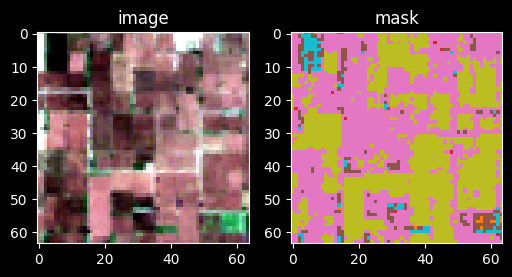

In [7]:
sample_imgs, sample_masks = next(iter(train_ds))
print('image batch:', sample_imgs.shape, sample_imgs.dtype)
print('mask batch: ', sample_masks.shape, sample_masks.dtype, 'unique:', np.unique(sample_masks.numpy()))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(sample_imgs[0])
axes[0].set_title('image')
axes[1].imshow(sample_masks[0, ..., 0], cmap='tab10', vmin=0, vmax=N_CLASSES - 1)
axes[1].set_title('mask')
plt.show()

## Class weights

A spot check of sampled masks showed heavy class imbalance (agriculture and
built-up dominate pixel counts; water and dense forest are minorities).
Plain cross-entropy would bias the model toward the majority classes, so
compute inverse-frequency weights from a sample of training masks to use in
the loss.

In [8]:
def compute_class_weights(mask_paths, n_classes, sample_size=5000, seed=0):
    rng = np.random.default_rng(seed)
    sample = rng.choice(mask_paths, size=min(sample_size, len(mask_paths)), replace=False)

    counts = np.zeros(n_classes, dtype=np.int64)
    for path in sample:
        labels = np.array(Image.open(path)) - 1
        for c in range(n_classes):
            counts[c] += np.sum(labels == c)

    freq = counts / counts.sum()
    weights = 1.0 / (freq + 1e-6)
    weights = weights / weights.sum() * n_classes
    return weights

class_weights = compute_class_weights(train_mask_paths, N_CLASSES)
for name, w in zip(CLASS_NAMES, class_weights):
    print(f'{name:>15}: {w:.3f}')

          water: 2.823
   dense forest: 2.480
  sparse forest: 0.534
    barren land: 0.284
       built up: 0.108
    agriculture: 0.062
    fallow land: 0.709


## U-Net architecture

A 4-level encoder/decoder (32→64→128→256 filters) with skip connections.
Original draft used a 5-level, 1024-filter U-Net sized for 256x256 inputs;
that's oversized for these 64x64 chips, so it's scaled down here.

In [9]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(filters, 3, activation='relu', padding='same')(x)
    return x

def build_unet(input_size=(IMG_SIZE, IMG_SIZE, N_CHANNELS), n_classes=N_CLASSES):
    inputs = layers.Input(input_size)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D(2)(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D(2)(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D(2)(c3)

    c4 = conv_block(p3, 256)

    # Decoder
    u5 = layers.Conv2DTranspose(128, 2, strides=2, padding='same')(c4)
    u5 = layers.concatenate([u5, c3])
    c5 = conv_block(u5, 128)

    u6 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(c5)
    u6 = layers.concatenate([u6, c2])
    c6 = conv_block(u6, 64)

    u7 = layers.Conv2DTranspose(32, 2, strides=2, padding='same')(c6)
    u7 = layers.concatenate([u7, c1])
    c7 = conv_block(u7, 32)

    outputs = layers.Conv2D(n_classes, 1, activation='softmax')(c7)

    return models.Model(inputs, outputs, name='unet')

model = build_unet()
model.summary()

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 8, 8, 128) │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 8, 8, 256) │    295,168 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 8, 8, 256) │    590,080 │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 16, 16,    │    131,200 │ conv2d_7[0][0]    │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 256)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    295,040 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_8[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 32, 32,    │     32,832 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,925,799 (7.35 MB)

 Trainable params: 1,925,799 (7.35 MB)

 Non-trainable params: 0 (0.00 B)

## Loss function

Weighted sparse categorical cross-entropy (using the class weights computed
above) combined with a Dice loss term, which helps further with the
imbalance by directly optimizing class overlap rather than per-pixel
likelihood.

In [10]:
class_weights_tensor = tf.constant(class_weights, dtype=tf.float32)

def weighted_sce(y_true, y_pred):
    y_true = tf.cast(tf.squeeze(y_true, axis=-1), tf.int32)
    per_pixel_loss = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    weights = tf.gather(class_weights_tensor, y_true)
    return tf.reduce_mean(per_pixel_loss * weights)

def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(tf.squeeze(y_true, axis=-1), tf.int32)
    y_true_oh = tf.one_hot(y_true, depth=N_CLASSES)
    intersection = tf.reduce_sum(y_true_oh * y_pred, axis=[1, 2])
    union = tf.reduce_sum(y_true_oh + y_pred, axis=[1, 2])
    dice = (2.0 * intersection + smooth) / (union + smooth)
    return 1.0 - tf.reduce_mean(dice)

def combined_loss(y_true, y_pred):
    return weighted_sce(y_true, y_pred) + dice_loss(y_true, y_pred)

## Compiling the model

Optimize with Adam. Track mean IoU and per-class IoU rather than pixel
accuracy, since accuracy is misleading on an imbalanced segmentation task
(a model predicting only "agriculture" everywhere would still score high
accuracy).

In [11]:
mean_iou_metric = tf.keras.metrics.MeanIoU(
    num_classes=N_CLASSES,
    sparse_y_true=True,
    sparse_y_pred=False,
    name='mean_iou',
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=combined_loss,
    metrics=[mean_iou_metric],
)

## Callbacks

Stop early and reduce the learning rate when validation mean IoU plateaus;
checkpoint the best weights seen during training.

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_mean_iou', mode='max', patience=4, restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_mean_iou', mode='max', factor=0.5, patience=2, min_lr=1e-6,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        'unet_sen2_lulc_best.keras', monitor='val_mean_iou', mode='max', save_best_only=True,
    ),
]

## Training

Train for up to 15 epochs on the subset; early stopping (patience 4 on
validation mean IoU) will typically cut this short once it stops improving.
For a full run, set `SUBSET = None` above and raise `epochs` — ideally on a
GPU runtime, since native-Windows TensorFlow trains on CPU only.

In [13]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks,
)

Epoch 1/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 105s 5s/step - loss: 1.3064 - mean_iou: 0.1001 - val_loss: 1.2607 - val_mean_iou: 0.1284 - learning_rate: 0.0010
Epoch 2/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 72s 4s/step - loss: 1.2368 - mean_iou: 0.1486 - val_loss: 1.1921 - val_mean_iou: 0.1722 - learning_rate: 0.0010
Epoch 3/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - loss: 1.1832 - mean_iou: 0.1825 - val_loss: 1.1595 - val_mean_iou: 0.1868 - learning_rate: 0.0010
Epoch 4/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 55s 3s/step - loss: 1.1557 - mean_iou: 0.1969 - val_loss: 1.1406 - val_mean_iou: 0.1803 - learning_rate: 0.0010
Epoch 5/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - loss: 1.1369 - mean_iou: 0.2056 - val_loss: 1.1273 - val_mean_iou: 0.2056 - learning_rate: 0.0010
Epoch 6/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 76s 4s/step - loss: 1.1353 - mean_iou: 0.2082 - val_loss: 1.1267 - val_mean_iou: 0.1939 - learning_rate: 0.0010
Epoch 7/15
19/19 ━━━━━━━━━━━━━━━━━━━━ 59s 3s/step - loss: 1.1256 - mean_iou: 0.2134 - val_loss: 1.1

## Training curves

Plot loss and mean IoU across epochs to check for overfitting or
under-training before evaluating on the held-out test set.

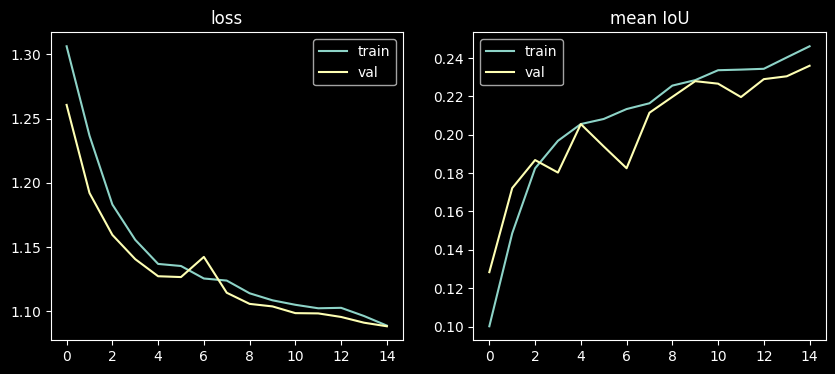

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')
axes[0].set_title('loss')
axes[0].legend()

axes[1].plot(history.history['mean_iou'], label='train')
axes[1].plot(history.history['val_mean_iou'], label='val')
axes[1].set_title('mean IoU')
axes[1].legend()

plt.show()

## Test set evaluation

Evaluate on the untouched test split for the final reported loss/mean IoU.

In [15]:
test_loss, test_mean_iou = model.evaluate(test_ds)
print(f'test loss: {test_loss:.4f}')
print(f'test mean IoU: {test_mean_iou:.4f}')

502/502 ━━━━━━━━━━━━━━━━━━━━ 654s 1s/step - loss: 1.0835 - mean_iou: 0.2435
test loss: 1.0835
test mean IoU: 0.2435


## Per-class IoU

Mean IoU hides which classes the model actually struggles with — recompute
IoU per class over the test set to see if the minority classes (water,
dense forest) are being learned or just ignored.

In [16]:
per_class_iou_metric = tf.keras.metrics.MeanIoU(
    num_classes=N_CLASSES, sparse_y_true=True, sparse_y_pred=False,
)

for images, masks in test_ds:
    preds = model.predict(images, verbose=0)
    per_class_iou_metric.update_state(masks, preds)

cm = per_class_iou_metric.total_cm.numpy()
intersection = np.diag(cm)
union = cm.sum(axis=0) + cm.sum(axis=1) - intersection
iou_per_class = intersection / np.maximum(union, 1e-6)

for name, iou in zip(CLASS_NAMES, iou_per_class):
    print(f'{name:>15}: {iou:.3f}')

          water: 0.062
   dense forest: 0.214
  sparse forest: 0.115
    barren land: 0.232
       built up: 0.247
    agriculture: 0.608
    fallow land: 0.227


## Visual check

Plot a few test images alongside their ground-truth and predicted masks for
a qualitative sense of where the model succeeds or fails.

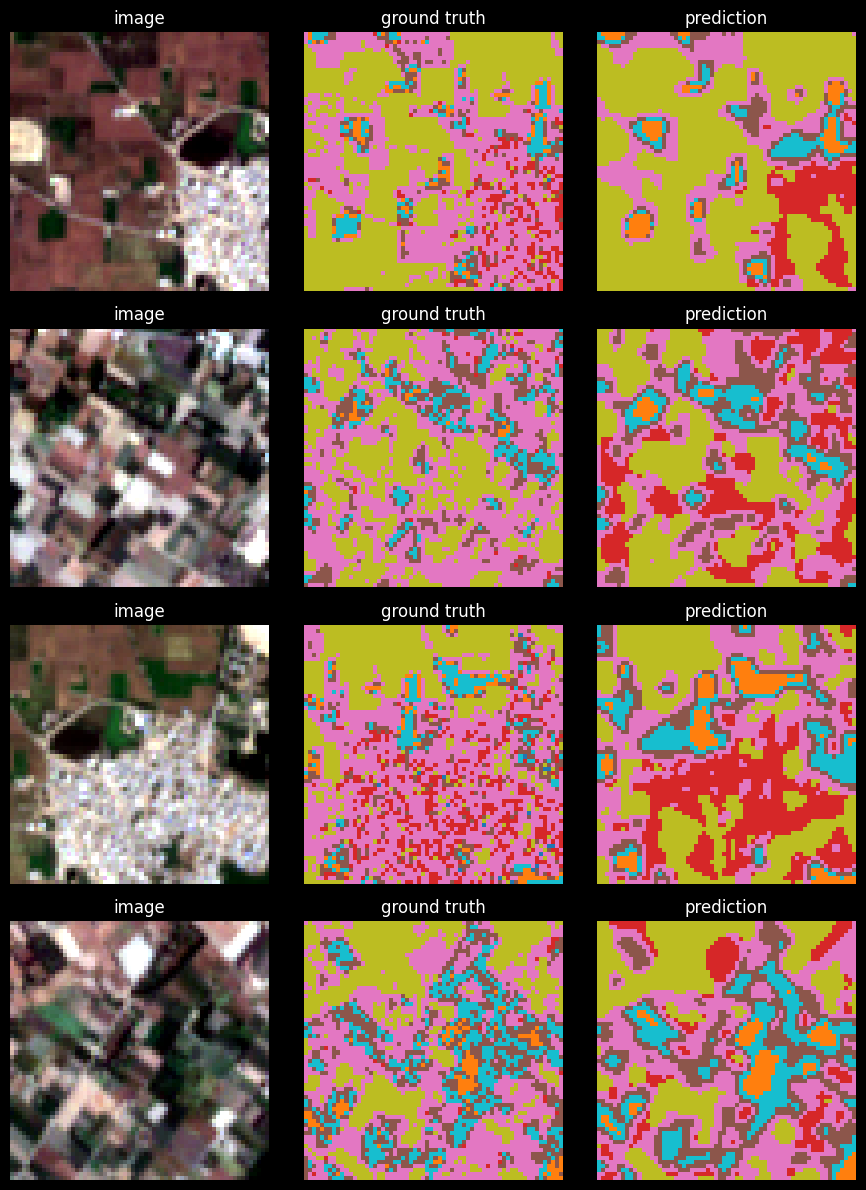

In [17]:
images, masks = next(iter(test_ds))
preds = model.predict(images, verbose=0)
pred_classes = np.argmax(preds, axis=-1)

n_show = 4
fig, axes = plt.subplots(n_show, 3, figsize=(9, 3 * n_show))
for i in range(n_show):
    axes[i, 0].imshow(images[i])
    axes[i, 0].set_title('image')
    axes[i, 1].imshow(masks[i, ..., 0], cmap='tab10', vmin=0, vmax=N_CLASSES - 1)
    axes[i, 1].set_title('ground truth')
    axes[i, 2].imshow(pred_classes[i], cmap='tab10', vmin=0, vmax=N_CLASSES - 1)
    axes[i, 2].set_title('prediction')
    for ax in axes[i]:
        ax.axis('off')

plt.tight_layout()
plt.show()